# Loading the dataset from roboflow and checking the GPU of Goole Collab

In [1]:
!nvidia-smi

Sun Nov 22 04:57:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
DRIVE_ROOT = "/content/drive/MyDrive/Segmentation_Assignment3_Viskom"
YOLO_ZIP = f"{DRIVE_ROOT}/data/panoptic-indoor-segmentation.v1-train-v1.yolov11.zip"
COCO_ZIP = f"{DRIVE_ROOT}/data/panoptic-indoor-segmentation.v1-train-v1.coco.zip"
RUNS_DIR = f"{DRIVE_ROOT}/runs"

In [3]:
!mkdir -p /content/data/yolo /content/data/coco
!mkdir -p "{RUNS_DIR}"
!unzip -q "{YOLO_ZIP}" -d /content/data/yolo
!unzip -q "{COCO_ZIP}" -d /content/data/coco

replace /content/data/yolo/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [8]:
import glob, os
for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"/content/data/yolo/{split}/images/*")
    mine = [p for p in imgs if os.path.basename(p).startswith("IMG_20261117_")]
    print(split, len(imgs), "images, own photos:", len(mine))

train 397 images, own photos: 0
valid 166 images, own photos: 0
test 409 images, own photos: 50


# Preparing for training and fixing the path


In [9]:
!pip -q install ultralytics

In [10]:
import yaml
with open("/content/data/yolo/data.yaml") as f:
    d = yaml.safe_load(f)
d["path"] = "/content/data/yolo"
d["train"] = "train/images"
d["val"] = "valid/images"
d["test"] = "test/images"
with open("/content/data/yolo/data_fixed.yaml", "w") as f:
    yaml.safe_dump(d, f)
print("classes:", d["nc"])

classes: 74


---

# The 3 Model for Segmentation
# YOLO11

1. YOLO11

YOLO Baseline with default augmentation

In [13]:
from ultralytics import YOLO
import time

t0 = time.time()
model = YOLO("yolo11s-seg.pt")
model.train(
    data="/content/data/yolo/data_fixed.yaml",
    imgsz=640,
    epochs=50,
    batch=16,
    seed=0,
    project=RUNS_DIR,
    name="yolo11s_default_aug",
)
print("GPU time (min):", round((time.time() - t0) / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_default_aug-3, nbs=64, nms=None, opset=Non

YOLO with no augmentation

In [14]:
t0 = time.time()
model = YOLO("yolo11s-seg.pt")
model.train(
    data="/content/data/yolo/data_fixed.yaml",
    imgsz=640,
    epochs=50,
    batch=16,
    seed=0,
    project=RUNS_DIR,
    name="yolo11s_no_aug",
    hsv_h=0, hsv_s=0, hsv_v=0,
    degrees=0, translate=0, scale=0, shear=0, perspective=0,
    flipud=0, fliplr=0,
    mosaic=0, mixup=0, copy_paste=0,
)
print("GPU time (min):", round((time.time() - t0) / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo/data_fixed.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0, flipud=0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=yolo11s_no_aug, nbs=64, nms=None, opset=None, optimize=False, optimize

YOLO with my augmentation

In [15]:
t0 = time.time()
model = YOLO("yolo11s-seg.pt")
model.train(
    data="/content/data/yolo/data_fixed.yaml",
    imgsz=640,
    epochs=50,
    batch=16,
    seed=0,
    project=RUNS_DIR,
    name="yolo11s_custom_aug",
    hsv_v=0.6, hsv_s=0.5,
    degrees=30, perspective=0.0005,
)
print("GPU time (min):", round((time.time() - t0) / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo/data_fixed.yaml, degrees=30, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.6, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_custom_aug, nbs=64, nms=None, opset=None, o

# Split test images in my photo and the originals dataset

In [16]:
import shutil, glob, os
SRC = "/content/data/yolo/test"
for name in ["own", "orig"]:
    os.makedirs(f"/content/data/{name}/images", exist_ok=True)
    os.makedirs(f"/content/data/{name}/labels", exist_ok=True)
for img in glob.glob(f"{SRC}/images/*"):
    base = os.path.basename(img)
    name = "own" if base.startswith("IMG_20261117_") else "orig"
    lbl = f"{SRC}/labels/{os.path.splitext(base)[0]}.txt"
    shutil.copy(img, f"/content/data/{name}/images/{base}")
    if os.path.exists(lbl):
        shutil.copy(lbl, f"/content/data/{name}/labels/")
for name in ["own", "orig"]:
    print(name, len(os.listdir(f"/content/data/{name}/images")), "images")

own 50 images
orig 359 images


save the dataset into each test set

In [17]:
import yaml
d = yaml.safe_load(open("/content/data/yolo/data_fixed.yaml"))
for name in ["own", "orig"]:
    y = dict(d)
    y["path"] = f"/content/data/{name}"
    y["train"] = "images"
    y["val"] = "images"
    y["test"] = "images"
    yaml.safe_dump(y, open(f"/content/data/{name}.yaml", "w"))

evaluate all 3 runs on both sets

In [19]:
import pandas as pd
runs = ["yolo11s_default_aug-3", "yolo11s_no_aug", "yolo11s_custom_aug"]
rows = []
for run in runs:
    m = YOLO(f"{RUNS_DIR}/{run}/weights/best.pt")
    for name in ["orig", "own"]:
        r = m.val(data=f"/content/data/{name}.yaml", imgsz=640, batch=16,
                  project=RUNS_DIR, name=f"eval_{run}_{name}")
        rows.append(dict(run=run, testset=name,
                         mask_map50=r.seg.map50, mask_map5095=r.seg.map))
df = pd.DataFrame(rows)
print(df)
df.to_csv(f"{RUNS_DIR}/eval_yolo_results.csv", index=False)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,095,454 parameters, 0 gradients, 33.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1032.5±765.3 MB/s, size: 57.0 KB)
val: Scanning /content/data/orig/labels... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 1.0Kit/s 0.3s
val: /content/data/orig/images/002_jpg.rf.b861ceff5fbafadfbee1475bf2682ad5.jpg: 1 duplicate labels removed
val: /content/data/orig/images/236_jpeg.rf.f301900c9577788667615d5a43f43ec3.jpg: 2 duplicate labels removed
val: New cache created: /content/data/orig/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.6it/s 8.9s
                   all        359       5341      0.486      0.224      0.208      0.148      0.445      0.218        0.2      0.126
              backpack         15         31   

---

# Mask R-CNN and Mask2Former

2. Mask R-CNN

In [6]:
import os, json, time, csv
import numpy as np, torch, torchvision
from PIL import Image
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from pycocotools.cocoeval import COCOeval
import torchvision.transforms.functional as TF

COCO_ROOT = "/content/data/coco"
torch.manual_seed(0); np.random.seed(0)

def load_split(split):
    return COCO(f"{COCO_ROOT}/{split}/_annotations.coco.json")

coco_train = load_split("train")
cats = [c for c in coco_train.loadCats(coco_train.getCatIds()) if c.get("supercategory") != "none"]
cat_ids = [c["id"] for c in cats]
cat_to_idx = {cid: i + 1 for i, cid in enumerate(cat_ids)}
idx_to_cat = {v: k for k, v in cat_to_idx.items()}
NUM_CLASSES = len(cat_ids)
print("classes:", NUM_CLASSES)

class CocoSeg(torch.utils.data.Dataset):
    def __init__(self, split, train=False):
        self.split, self.train = split, train
        self.coco = coco_train if split == "train" else load_split(split)
        self.ids = sorted(self.coco.getImgIds())
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        info = self.coco.loadImgs(iid)[0]
        H, W = info["height"], info["width"]
        img = Image.open(f"{COCO_ROOT}/{self.split}/{info['file_name']}").convert("RGB")
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=iid, iscrowd=False))
        boxes, labels, masks = [], [], []
        for a in anns:
            if a["category_id"] not in cat_to_idx:
                continue
            x, y, w, h = a["bbox"]
            if w < 1 or h < 1:
                continue
            m = self.coco.annToMask(a)
            if m.sum() == 0:
                continue
            boxes.append([x, y, x + w, y + h])
            labels.append(cat_to_idx[a["category_id"]])
            masks.append(m)
        img = TF.to_tensor(img)
        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "masks": torch.from_numpy(np.stack(masks)) if masks else torch.zeros((0, H, W), dtype=torch.uint8),
        }
        if self.train and torch.rand(1) < 0.5:
            img = img.flip(-1)
            target["masks"] = target["masks"].flip(-1)
            b = target["boxes"].clone()
            b[:, [0, 2]] = W - target["boxes"][:, [2, 0]]
            target["boxes"] = b
        return img, target

def collate(batch):
    return tuple(zip(*batch))

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
classes: 74


In [7]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import pandas as pd
device = "cuda"
RUN = f"{RUNS_DIR}/maskrcnn_r50fpn"
model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=640, max_size=640)
in_f = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_f, NUM_CLASSES + 1)
in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, NUM_CLASSES + 1)
model.load_state_dict(torch.load(f"{RUN}/last.pt", map_location="cpu"))
model.to(device)
print(pd.read_csv(f"{RUN}/results.csv").tail(3))

    epoch      loss        lr    minutes
47     48  0.299584  0.000020  35.374339
48     49  0.299896  0.000005  36.093930
49     50  0.299599  0.000000  36.820987


In [ ]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
device = "cuda"
model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights="DEFAULT", min_size=640, max_size=640)
in_f = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_f, NUM_CLASSES + 1)
in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, NUM_CLASSES + 1)
model.to(device)

EPOCHS = 50
BATCH = 4
LR = 0.005
RUN = f"{RUNS_DIR}/maskrcnn_r50fpn"
os.makedirs(RUN, exist_ok=True)

loader = torch.utils.data.DataLoader(CocoSeg("train", train=True), batch_size=BATCH,
                                     shuffle=True, num_workers=2, collate_fn=collate)
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler()

In [22]:
t0 = time.time()
with open(f"{RUN}/results.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epoch", "loss", "lr", "minutes"])
    for ep in range(1, EPOCHS + 1):
        model.train()
        tot = 0
        for imgs, tgts in loader:
            imgs = [i.to(device) for i in imgs]
            tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
            with torch.autocast("cuda"):
                loss = sum(model(imgs, tgts).values())
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += loss.item()
        sched.step()
        mins = (time.time() - t0) / 60
        wr.writerow([ep, tot / len(loader), opt.param_groups[0]["lr"], mins])
        f.flush()
        torch.save(model.state_dict(), f"{RUN}/last.pt")
        print(ep, round(tot / len(loader), 4), round(mins, 1), "min")
print("GPU time (min):", round((time.time() - t0) / 60, 1))

1 2.709 0.7 min
2 1.9927 1.4 min
3 1.684 2.1 min
4 1.4822 2.9 min
5 1.3241 3.6 min
6 1.2129 4.3 min
7 1.1319 5.0 min
8 1.0268 5.8 min
9 0.9823 6.5 min
10 0.8867 7.2 min
11 0.845 7.9 min
12 0.77 8.6 min
13 0.7392 9.3 min
14 0.7115 10.1 min
15 0.6719 10.8 min
16 0.64 11.5 min
17 0.5992 12.3 min
18 0.5722 13.0 min
19 0.5627 13.7 min
20 0.5314 14.5 min
21 0.5063 15.2 min
22 0.4918 15.9 min
23 0.4702 16.6 min
24 0.4503 17.4 min
25 0.4366 18.1 min
26 0.4229 18.8 min
27 0.4139 19.5 min
28 0.4053 20.3 min
29 0.397 21.0 min
30 0.3799 21.7 min
31 0.3687 22.5 min
32 0.3592 23.2 min
33 0.3507 23.9 min
34 0.342 24.7 min
35 0.3393 25.4 min
36 0.3269 26.1 min
37 0.3274 26.8 min
38 0.3212 27.6 min
39 0.3106 28.3 min
40 0.311 29.0 min
41 0.3074 29.7 min
42 0.3049 30.5 min
43 0.3058 31.2 min
44 0.3112 32.2 min
45 0.3024 33.1 min
46 0.3028 33.9 min
47 0.3012 34.6 min
48 0.2996 35.4 min
49 0.2999 36.1 min
50 0.2996 36.8 min
GPU time (min): 36.8


In [8]:
model.roi_heads.score_thresh = 0.001
model.eval()
gt = load_split("test")
all_ids = sorted(gt.getImgIds())
own = [i for i in all_ids if gt.imgs[i]["file_name"].startswith("IMG_20261117_")]
own_set = set(own)
subsets = {"own": own, "orig": [i for i in all_ids if i not in own_set]}
print({k: len(v) for k, v in subsets.items()})

results = []
with torch.no_grad():
    for iid in all_ids:
        info = gt.imgs[iid]
        img = TF.to_tensor(Image.open(f"{COCO_ROOT}/test/{info['file_name']}").convert("RGB")).to(device)
        out = model([img])[0]
        for k in range(len(out["scores"])):
            m = (out["masks"][k, 0] > 0.5).cpu().numpy().astype(np.uint8)
            rle = mask_utils.encode(np.asfortranarray(m))
            rle["counts"] = rle["counts"].decode()
            results.append({"image_id": iid, "category_id": idx_to_cat[int(out["labels"][k])],
                            "segmentation": rle, "score": float(out["scores"][k])})
        del out, img
        torch.cuda.empty_cache()
dt = gt.loadRes(results)

rows = []
for name, ids in subsets.items():
    E = COCOeval(gt, dt, "segm")
    E.params.imgIds = ids
    E.evaluate(); E.accumulate(); E.summarize()
    rows.append(dict(run="maskrcnn_r50fpn", testset=name,
                     mask_map50=E.stats[1], mask_map5095=E.stats[0]))
df = pd.DataFrame(rows)
print(df)
df.to_csv(f"{RUN}/eval_results.csv", index=False)

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
{'own': 50, 'orig': 359}
Loading and preparing results...
DONE (t=1.10s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.61s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.054
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.090
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.051
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.055
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.170
 Average Recall     (AR) @[ IoU=0.50:0.9

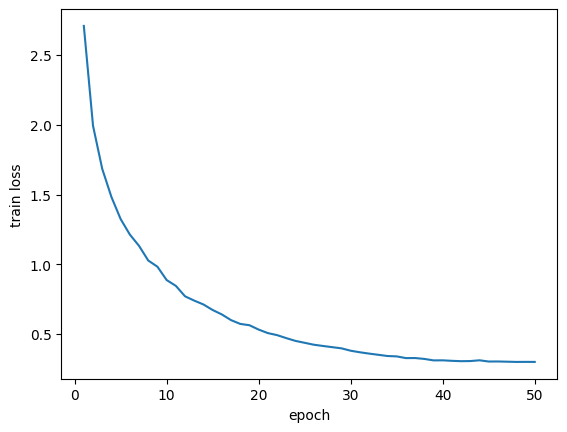

In [9]:
import pandas as pd, matplotlib.pyplot as plt
d = pd.read_csv(f"{RUN}/results.csv")
plt.plot(d.epoch, d.loss)
plt.xlabel("epoch"); plt.ylabel("train loss")
plt.savefig(f"{RUN}/loss_curve.png")
plt.show()

3. Mask2Former

In [10]:
!pip -q install transformers
from transformers import Mask2FormerForUniversalSegmentation, Mask2FormerImageProcessor
import torch.nn.functional as F

CKPT = "facebook/mask2former-swin-tiny-coco-instance"
id2label = {i: str(c["name"]) for i, c in enumerate(cats)}
processor = Mask2FormerImageProcessor.from_pretrained(CKPT)
model = Mask2FormerForUniversalSegmentation.from_pretrained(
    CKPT, id2label=id2label, ignore_mismatched_sizes=True).to(device)

preprocessor_config.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/79.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  190MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                    

In [11]:
S = 640
mean = torch.tensor(processor.image_mean).view(3, 1, 1)
std = torch.tensor(processor.image_std).view(3, 1, 1)

def m2f_collate(batch):
    pix, mlab, clab = [], [], []
    for img, t in batch:
        img = F.interpolate(img[None], size=(S, S), mode="bilinear", align_corners=False)[0]
        pix.append((img - mean) / std)
        mlab.append(F.interpolate(t["masks"][None].float(), size=(S, S), mode="nearest")[0])
        clab.append(t["labels"] - 1)
    return torch.stack(pix), mlab, clab

EPOCHS = 20
BATCH = 4
USE_AMP = True
RUN2 = f"{RUNS_DIR}/mask2former_swint"
os.makedirs(RUN2, exist_ok=True)

ds = CocoSeg("train", train=True)
ds.ids = [i for i in ds.ids if len(ds.coco.getAnnIds(imgIds=i)) > 0]
loader = torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=True,
                                     num_workers=2, collate_fn=m2f_collate)
bb = [p for n, p in model.named_parameters() if "encoder" in n and "pixel_level_module" in n]
rest = [p for n, p in model.named_parameters() if not ("encoder" in n and "pixel_level_module" in n)]
opt = torch.optim.AdamW([{"params": bb, "lr": 1e-5}, {"params": rest, "lr": 1e-4}], weight_decay=0.05)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

/tmp/ipykernel_1243/2911326999.py:27: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [12]:
t0 = time.time()
with open(f"{RUN2}/results.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["epoch", "loss", "minutes"])
    for ep in range(1, EPOCHS + 1):
        model.train()
        tot = 0
        for pix, mlab, clab in loader:
            with torch.autocast("cuda", enabled=USE_AMP):
                out = model(pixel_values=pix.to(device),
                            mask_labels=[m.to(device) for m in mlab],
                            class_labels=[c.to(device) for c in clab])
            opt.zero_grad()
            scaler.scale(out.loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
            scaler.step(opt)
            scaler.update()
            tot += out.loss.item()
        mins = (time.time() - t0) / 60
        wr.writerow([ep, tot / len(loader), mins]); f.flush()
        torch.save(model.state_dict(), f"{RUN2}/last.pt")
        print(ep, round(tot / len(loader), 4), round(mins, 1), "min")
print("GPU time (min):", round((time.time() - t0) / 60, 1))

1 75.7205 1.6 min
2 51.3419 3.3 min
3 44.0707 4.9 min
4 39.3441 6.6 min
5 35.5993 8.2 min
6 32.4614 9.9 min
7 29.8423 11.5 min
8 28.5372 13.2 min
9 26.1394 14.8 min
10 24.4418 16.5 min
11 23.3397 18.1 min
12 21.9099 19.8 min
13 21.0242 21.4 min
14 19.9217 23.1 min
15 19.0521 24.7 min
16 18.3808 26.4 min
17 18.1635 28.0 min
18 16.7264 29.7 min
19 16.4886 31.3 min
20 15.707 33.0 min
GPU time (min): 33.0


In [14]:
model.eval()
gt = load_split("test")
all_ids = sorted(gt.getImgIds())
own = [i for i in all_ids if gt.imgs[i]["file_name"].startswith("IMG_20261117_")]
own_set = set(own)
subsets = {"own": own, "orig": [i for i in all_ids if i not in own_set]}
print({k: len(v) for k, v in subsets.items()})

results = []
with torch.no_grad():
    for iid in all_ids:
        info = gt.imgs[iid]
        H, W = info["height"], info["width"]
        img = TF.to_tensor(Image.open(f"{COCO_ROOT}/test/{info['file_name']}").convert("RGB"))
        img = F.interpolate(img[None], size=(S, S), mode="bilinear", align_corners=False)[0]
        out = model(pixel_values=((img - mean) / std)[None].to(device))
        res = processor.post_process_instance_segmentation(
            out, threshold=0.05, target_sizes=[(S, S)], return_binary_maps=True)[0]
        for seg, si in zip(res["segmentation"], res["segments_info"]):
            seg = F.interpolate(seg[None, None].float(), size=(H, W), mode="nearest")[0, 0]
            m = (seg > 0.5).cpu().numpy().astype(np.uint8)
            rle = mask_utils.encode(np.asfortranarray(m))
            rle["counts"] = rle["counts"].decode()
            results.append({"image_id": iid, "category_id": cat_ids[si["label_id"]],
                            "segmentation": rle, "score": float(si["score"])})
        del out, res
        torch.cuda.empty_cache()
dt = gt.loadRes(results)

rows = []
for name, ids in subsets.items():
    E = COCOeval(gt, dt, "segm")
    E.params.imgIds = ids
    E.evaluate(); E.accumulate(); E.summarize()
    rows.append(dict(run="mask2former_swint", testset=name,
                     mask_map50=E.stats[1], mask_map5095=E.stats[0]))
df = pd.DataFrame(rows)
print(df)
df.to_csv(f"{RUN2}/eval_results.csv", index=False)

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
{'own': 50, 'orig': 359}
Loading and preparing results...
DONE (t=0.41s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.33s).
Accumulating evaluation results...
DONE (t=0.12s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.089
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.143
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.088
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.008
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.090
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.131
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.167
 Average Recall     (AR) @[ IoU=0.50:0.9